# Pulsed (Broadband) Fresnel Propagation Through a Lens

Explores propagating a **pulsed, broadband** Gaussian beam (finite pulse duration `tau`, not monochromatic) through an ideal thin lens using a direct Fresnel diffraction integral evaluated frequency-by-frequency (FFT in time/frequency, Bessel-function radial integral), rather than the discrete Hankel Transform (DHT) used elsewhere in this repo. Produces time-resolved on-axis intensity maps at the lens (z=0) and after the lens (z=L).

Current code (`common/`, `without_zernike/`) is monochromatic/CW-only — this notebook is the only exploration of pulsed/broadband propagation in either repo, which is why it's being kept despite being unmaintained and exploratory.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv,jn_zeros
from scipy.optimize import curve_fit
from scipy.integrate import trapezoid,simpson,romb
import math
from numpy.fft import *
font = {'size'   : 26}

plt.rc('font', **font)
plt.rcParams['figure.figsize'] = (12,10)

In [2]:
def DHTarrays(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    r=R*Zeroes[:N]/Zeroes[N-1]
    k=Zeroes[:N]/R
    return np.array([r,k])

This function defines the Transform Matrix for the Hankel Transform
* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function
* `T_R2K` transforms from r space to k space
* `T_K2R` transforms from k space to r space


In [3]:
def DHTtransformMatrix(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    alpha=Zeroes[:N]
    kR = alpha[N-1]
    kmax = kR/R;
    T = jv(ell,np.outer(alpha,alpha)/kR) / np.outer( abs(jv(ell+1,alpha)),abs(jv(ell+1,alpha)) ) / kR;
    #print(T)
    A = abs(jv(ell+1,alpha));
    T_R2K = 4.0*np.pi*(R/kmax)*T * A[:, None] / A[None,:] 
    T_K2R = (1/np.pi)*(kmax/R)*T * A[:, None] / A[None,:] 

    return T_R2K,T_K2R

In [4]:
#constants
cl = 3e8;

#input parameters
tau = 100e-15; #pulse duration
wi = 0.02; #initial spot size
f = 1; #lens focal length
L = f-0.05; #where to propagate field to
lambda0 = 1.054e-6; #intial wavelength

zri = np.pi*wi**2/lambda0; #incident Rayleigh range
wL = wi*np.sqrt((1-L/f)**2+(L/zri)**2); #predicting spot size at z=L

In [5]:
#grid parameters
nt =256; #number of time grid points
nr = 100; #number of far-field grid points
nrprime =1000; #number of near-field grid points
rmaxL = 3; #multiple of far field spot to determine max grid point
t = np.linspace(-20*tau,20*tau,nt); #time array
deltomg = 2*np.pi/(max(t)-min(t))*np.linspace(-nt/2,nt/2-1,nt); #frequency array
omg0 = 2*np.pi*cl/lambda0; #central frequency
omg = omg0+deltomg;
Omg = np.outer(np.ones(nrprime),omg);
domg = deltomg[2]-deltomg[1];

In [6]:
rmaxL*wL

0.003000380918779139

In [7]:
#radial arrays
rprime = np.linspace(0,3*wi,nrprime); 
[r,kr] = DHTarrays(nr,rmaxL*wL,0); #loading in radial data/transform matrices for Hankel transform
[T_R2K,T_K2R] = DHTtransformMatrix(nr,rmaxL*wL,0); 
[T,Rprime] = np.meshgrid(t,rprime); #near field mesh grid

In [8]:
#initializing field in r & t space at lens
Ert0 = np.exp(-Rprime**2/wi**2)*np.exp(-T**2/tau**2);
#Fourier transforming field to r and frequency space
Erw0 = 2*np.pi/domg*ifftshift(ifft(Ert0,axis=1),axes=1);
#applying lens phase
Erw0 = Erw0*np.exp(-1j*Omg*Rprime**2/(2*cl*f));
Ert0 = domg/(2*np.pi)*fft(fftshift(Erw0,axes=1),axis=1);

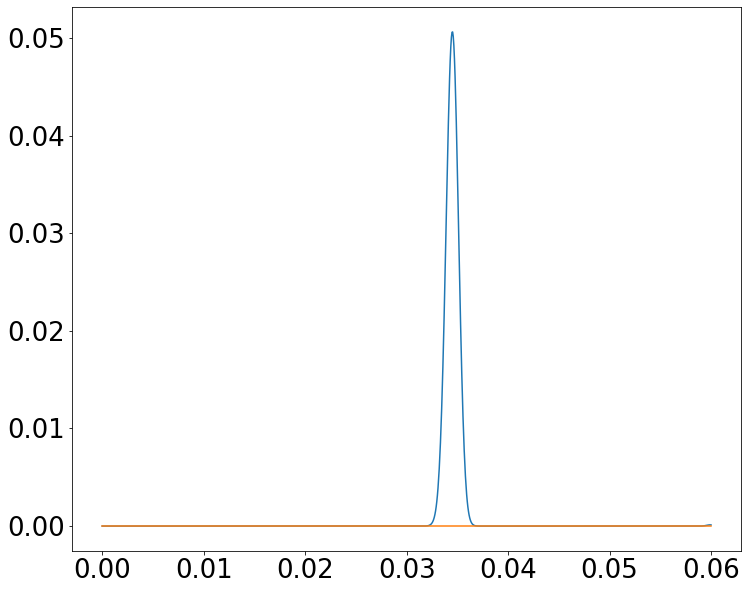

In [16]:
plt.plot(rprime,np.abs(Ert0[:,0]))
plt.plot(rprime,np.abs(Erw0[:,0]))

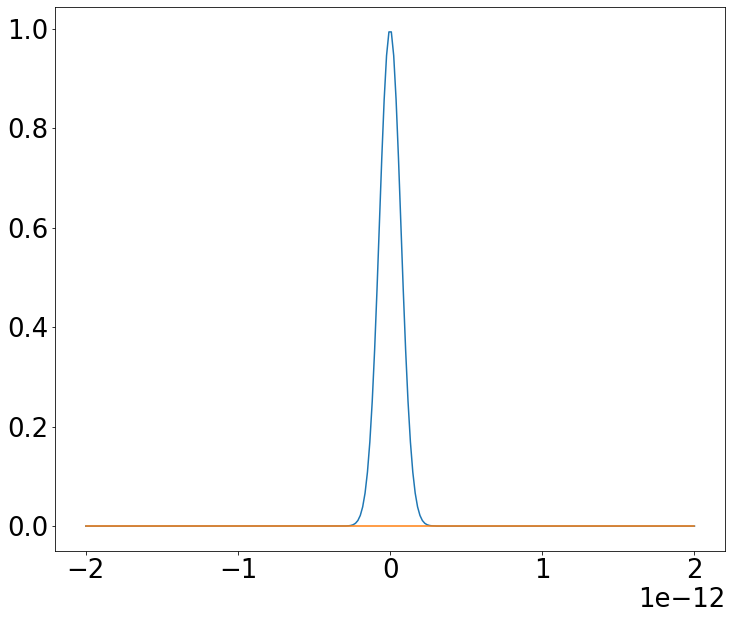

In [18]:
plt.plot(t,np.abs(Ert0[0]))
plt.plot(t,np.abs(Erw0[10]))

In [10]:
np.shape(Ert0)

(1000, 256)

In [26]:
#starting Fresnel integral
coef = (rprime[1]-rprime[0])*(omg)/(1j*cl*L);

Erw=np.empty((nr,nt),dtype=np.cfloat)
for it in range(nt): #loop over frequency components
    integrand = (rprime.T*Erw0[:,it]*np.exp(1j*(omg[it])*(rprime.T)**2/(2*cl*L)));
    
    bess = jv(0,omg[it]*np.outer(r,rprime)/(L*cl));
    
    curvature_z = np.exp(1j*omg[it]*r**2/(2*L*cl));
    
    Erw[:,it] = coef[it]*curvature_z*np.sum(bess*integrand,axis=1);
    
ErtL = domg/(2*np.pi)*fft(fftshift(Erw,axes=1),axis=1);

In [30]:
t

array([-2.00000000e-12, -1.98431373e-12, -1.96862745e-12, -1.95294118e-12,
       -1.93725490e-12, -1.92156863e-12, -1.90588235e-12, -1.89019608e-12,
       -1.87450980e-12, -1.85882353e-12, -1.84313725e-12, -1.82745098e-12,
       -1.81176471e-12, -1.79607843e-12, -1.78039216e-12, -1.76470588e-12,
       -1.74901961e-12, -1.73333333e-12, -1.71764706e-12, -1.70196078e-12,
       -1.68627451e-12, -1.67058824e-12, -1.65490196e-12, -1.63921569e-12,
       -1.62352941e-12, -1.60784314e-12, -1.59215686e-12, -1.57647059e-12,
       -1.56078431e-12, -1.54509804e-12, -1.52941176e-12, -1.51372549e-12,
       -1.49803922e-12, -1.48235294e-12, -1.46666667e-12, -1.45098039e-12,
       -1.43529412e-12, -1.41960784e-12, -1.40392157e-12, -1.38823529e-12,
       -1.37254902e-12, -1.35686275e-12, -1.34117647e-12, -1.32549020e-12,
       -1.30980392e-12, -1.29411765e-12, -1.27843137e-12, -1.26274510e-12,
       -1.24705882e-12, -1.23137255e-12, -1.21568627e-12, -1.20000000e-12,
       -1.18431373e-12, -

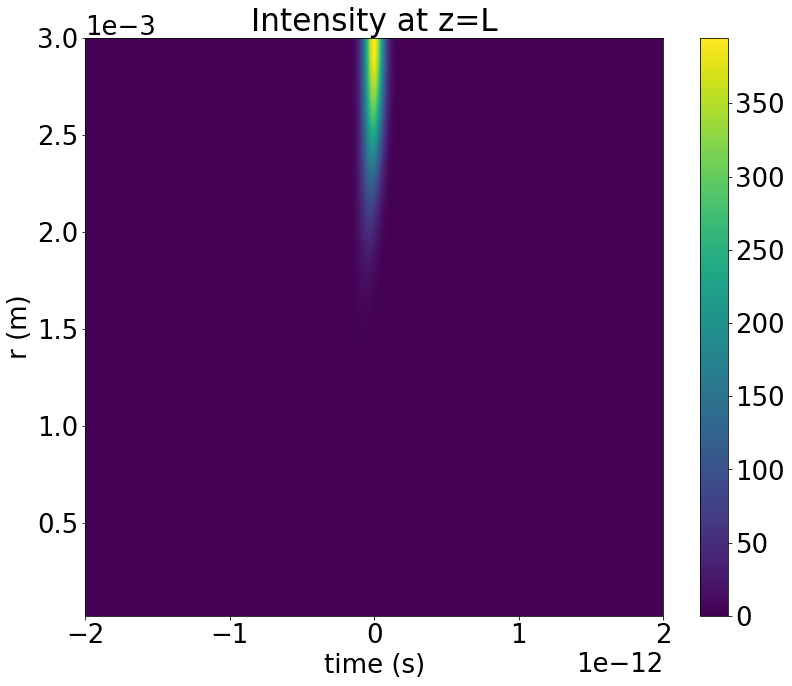

In [81]:
#fig, ax = plt.subplots()
et=[min(t),max(t),min(r),max(r)]
a=(max(t)-min(t))/(max(r)-min(r))
plt.imshow(np.abs(ErtL)**2,extent=[min(t),max(t),min(r),max(r)],aspect=a)
plt.colorbar()
plt.xlabel('time (s)')
plt.ylabel('r (m)')
plt.title('Intensity at z=L')
plt.ticklabel_format(axis='both', style='sci', scilimits=(0,0))
plt.tight_layout()
plt.savefig('fresnel_z-L')

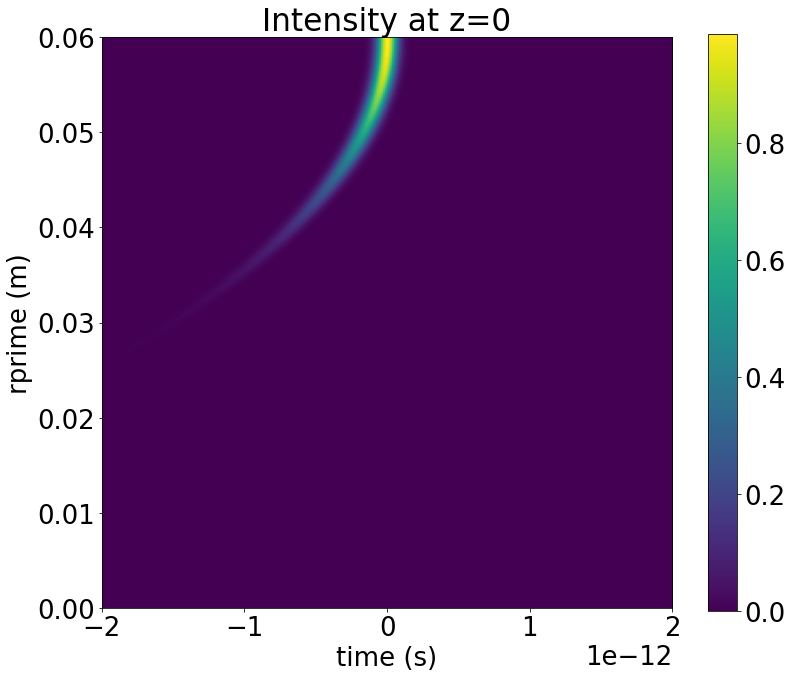

In [76]:
#fig, ax = plt.subplots()
et=[min(t),max(t),min(rprime),max(rprime)]
a=(max(t)-min(t))/(max(rprime)-min(rprime))
plt.imshow(np.abs(Ert0)**2,extent=[min(t),max(t),min(rprime),max(rprime)],aspect=a)
plt.xlabel('time (s)')
plt.ylabel('rprime (m)')
plt.title('Intensity at z=0')
plt.colorbar()
plt.tight_layout()

plt.savefig('fresnel_z-0')

In [83]:
rprime[1]-rprime[0]

6.006006006006006e-05